# Passo 1: configurar o ambiente

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns #roda em cima do matplotlib (é pra gráfico mais bonitinho)
import sklearn
df = pd.read_csv('Titanic.csv', sep=',')
display(df.head())

# Passo 2: Entendendo os dados
Um bom analista não sai criando dados como se não houvesse amanhã. Ele busca entender a base de dados.

In [ ]:
linhas, colunas = df.shape # Com o df, ta desmembrando a tupla.
print(f'A base de dados possui {linhas} linhas e {colunas} colunas') #devolve uma tupla!!!!!! tupla = conjunto de dados

print(df.info())

# Passo 3: Estatística descritiva

In [ ]:
display(df.describe().round(2))
df.describe(exclude='number')

# Passo 4: Contagem de categorias
Como separar e contar os dados por categoria?

In [ ]:
print(df['Sobreviveu'].value_counts())
print('-------------------------')
pct = df['Sobreviveu'].value_counts(normalize=True).mul(100).round(3)
print(pct)

# Passo 5: Limpeza dos dados.
Vamos tratar os dados que faltam. Valores vazios ou nulos alteram o resultado

In [17]:
ausentes = df.isna().sum()

pct_ausentes = df.isna().mean() * 100

df_ausentes = pd.DataFrame({"Dados Ausentes": ausentes, "Percentual": pct_ausentes})

df_ausentes = df_ausentes[df_ausentes['Dados Ausentes'] > 0]

df_ausentes = df_ausentes.sort_values(by='Dados Ausentes', ascending=False)

display(df_ausentes)

# Procurar linhas duplicadas:
print(f"Linhas duplicadas: {df.duplicated().sum()}")
print(f"IdPassageiro é único? {df["IdPassageiro"].is_unique}")

,Dados Ausentes,Percentual
Cabine,687,77.104377
Idade,177,19.865320
PortoEmbarque,2,0.224467


Linhas duplicadas: 0
IdPassageiro é único? True


# Passo 6: Tratar o PortoDeEmbarque
Preencha os dois valores vazios com a moda (valor q mais se repete)

In [20]:
porto_mais_comum = df["PortoEmbarque"].mode()[0]
print(porto_mais_comum)

df["PortoEmbarque"] = df["PortoEmbarque"].fillna(porto_mais_comum)

print(f"Ausentes :{df["PortoEmbarque"].isna().sum()}")

0    Southampton
Name: PortoEmbarque, dtype: str
Ausentes :2


# Passo 7: Tratar Cabine
Criar uma nova coluna pra transformar a coluna cabine em uma informação relevante

In [ ]:
df['TemCabine'] = df['Cabine'].notna().astype(int)
df['Deck'] = df['Cabine'].str[0].fillna('Desconhecido')
display(df['TemCabine'].value_counts())
df['Deck'].value_counts()
display(df.tail())

# Passo 8: Tratar a idade
Levar em consideração a idade, classe e sexo. Vamos preencher valores faltantes com a mediana

In [33]:
display(df.groupby(["Classe", "Sexo"])["Idade"].median().unstack())

#Criar uma nova coluna
df["IdadeImputada"] = df["Idade"].isna().astype(int)

#Criar uma serie com as medianas por grupo do mesmo tamanho dos dados faltantes
mediana_grupo = df.groupby(["Classe", "Sexo"])["Idade"].transform("median")
df["Idade"] = df["Idade"].fillna(mediana_grupo)
df["Idade"].isna().sum()

Sexo,feminino,masculino
Classe,,
1,35.0,40.0
2,28.0,30.0
3,21.5,25.0


np.int64(0)

# Passo 9: Engenharia de atributos
Calcular quantas pessoas de cada família estavam abordo

In [ ]:
df["TamanhoFamilia"] = df["IrmaosConjuges"] + df["PaisFilhos"] + 1
df["ViajaSozinho"] = (df["TamanhoFamilia"] == 1).astype(int)
print(f"Sozinhos: {df["ViajaSozinho"].sum()}")
df["TamanhoFamilia"].value_counts().sort_index()

# Passo 10: Faixas Etárias


In [36]:
intervalos = [0, 12, 18, 30, 45, 60, np.inf]
rotulos = ["Criança", "Adolescente", "Jovem Adulto", "Adulto", "Meia-Idade", "Idoso"]
df["FaixaEtaria"] = pd.cut(df["Idade"], bins=intervalos, labels=rotulos, right=False)
display(df["FaixaEtaria"].value_counts(sort=False))

FaixaEtaria
Criança          68
Adolescente      45
Jovem Adulto    409
Adulto          254
Meia-Idade       89
Idoso            26
Name: count, dtype: int64

# Passo 11: Histograma das idades


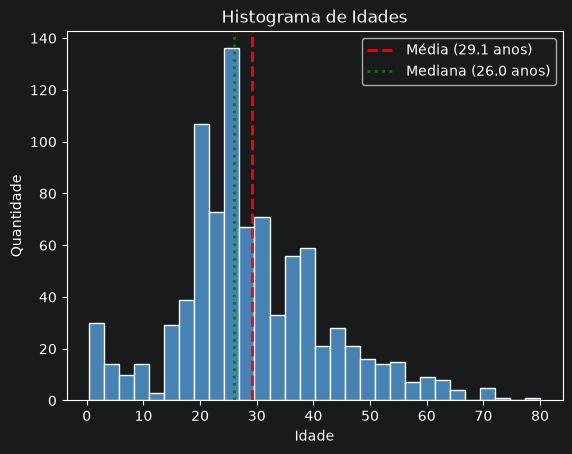

In [39]:
idades = df["Idade"]
fig, ax = plt.subplots()

ax.hist(idades, bins=30, color='steelblue', edgecolor='white')
ax.axvline(idades.mean(), color="red", linestyle="--", linewidth=2,label=f"Média ({idades.mean():.1f} anos)")
ax.axvline(idades.median(), color="green", linestyle=":", linewidth=2,label=f"Mediana ({idades.median():.1f} anos)")
ax.set_title("Histograma de Idades")
ax.set_xlabel("Idade")
ax.set_ylabel("Quantidade")
ax.legend()
plt.show()